# 15 - Capillary Pressure & Saturation-Height

**Part B - Petrophys Curriculum**

Water saturation from resistivity (Archie) tells you the fluid content *at each
depth independently*. A **saturation-height model** does something different and
deeper: it predicts $S_w$ from the **rock quality (porosity, permeability)** and
the **height above the free-water level (FWL)**, grounded in the physics of
**capillary pressure**. It lets you populate $S_w$ where logs are poor, build a
consistent 3-D saturation model, and QC the resistivity-based $S_w$.

This lesson demonstrates the `petrophys.interpretation.saturation.height`
module - capillary-pressure primitives, the Leverett J-function, a fitted
J-function model, and a log-column Sw-vs-depth predictor - using the COSTA
carbonate well **HW-3**. Its LAS file covers only the **Kharaib-2 reservoir
interval**, not the whole well. HW-3 ships no laboratory $P_c$ curve, so the
J-function is fitted the field way, from core-corrected rock-quality curves and
an assumed FWL; the library's single-plug lab-curve fitter (`fit_brooks_corey`)
is referenced but not demonstrated - we do not fabricate lab data.

Section 3b adds a separate real-data FWL interpretation for **35/11-13** using
MDT formation pressures and the original report plot. Its contact is not used
as the FWL of HW-3.

## Learning goals

- Convert between **capillary pressure ($P_c$)** and **height above the FWL**,
  and understand the buoyancy that lifts hydrocarbon into the pore system.
- Normalise Pc across rock qualities with the **Leverett J-function**.
- **Fit** a J-function ($S_w = a\,J^b$) to porosity, permeability and
  saturation data, and know when the single-plug Brooks-Corey fitter applies
  instead.
- Convert a **laboratory** Pc (air-mercury) to **reservoir** conditions.
- Predict **$S_w$ versus depth from logs** with a fitted model + an FWL depth,
  and overlay it on the log-derived $S_w$.
- Fit oil/water pressure gradients using QC-selected MDT points on a TVD datum,
  and compare their intersection with a reported FWL.

## Why this matters (the physics)

Above the free-water level, buoyancy of the lighter hydrocarbon against the
denser water creates a **capillary pressure** that forces water out of the
larger pores first. In field units:

$$P_c = 0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})\,h \quad [\text{psi}],\; h\text{ in ft}$$

so **height above the FWL is just a rescaled capillary pressure**. At a given
height, a *tight* rock (small pores, high entry pressure) holds **more** water
than a *good* rock. To compare rocks of different quality on one curve, Leverett
defined the dimensionless **J-function**:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\,\sqrt{\frac{k}{\phi}}$$

which folds in each rock's $k/\phi$. Fitting $S_w = a\,J^b$ once then lets us map
**any** ($k,\phi,h$) triple to a saturation - the engine of a saturation-height
model.

### Prerequisites
Work through Part A water-saturation (07) and permeability (08) first. Knowing
Archie $S_w$ and the porosity/permeability curves will make the log overlay at
the end meaningful.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.interpretation.saturation.height import (
    # capillary primitives
    pc_from_height, height_from_pc, convert_pc_lab_to_reservoir,
    leverett_j, pc_from_j, FLUID_SYSTEMS,
    # fitted models
    fit_j_function, saturation_height_from_logs,
)

print("petrophys", pp.__version__)
print("fluid systems (IFT dyne/cm, contact angle deg):")
for name, (ift, theta) in FLUID_SYSTEMS.items():
    print("  %-12s IFT=%6.1f  theta=%5.1f" % (name, ift, theta))

petrophys 3.0.0
fluid systems (IFT dyne/cm, contact angle deg):
  air_mercury  IFT= 480.0  theta=140.0
  air_brine    IFT=  72.0  theta=  0.0
  oil_brine    IFT=  30.0  theta= 30.0
  gas_brine    IFT=  50.0  theta=  0.0


## 1. Capillary pressure and height above the FWL

The `pc_from_height` / `height_from_pc` pair converts between the two using the
buoyancy gradient $0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})$. Below we use an oil
column: water SG = 1.0, oil SG = 0.8.

In [2]:
sg_water, sg_oil = 1.0, 0.8
heights = np.array([0, 25, 50, 100, 200, 400])   # ft above FWL
pc = pc_from_height(heights, sg_water=sg_water, sg_hc=sg_oil)

tbl = pd.DataFrame({'height above FWL (ft)': heights, 'Pc (psi)': pc})
print(tbl.to_string(index=False))
print()
# round-trip check
h_back = height_from_pc(pc, sg_water=sg_water, sg_hc=sg_oil)
print('round-trip height_from_pc matches:', np.allclose(h_back, heights))
grad = 0.433 * (sg_water - sg_oil)
print('buoyancy gradient = %.4f psi/ft' % grad)

 height above FWL (ft)  Pc (psi)
                     0     0.000
                    25     2.165
                    50     4.330
                   100     8.660
                   200    17.320
                   400    34.640

round-trip height_from_pc matches: True
buoyancy gradient = 0.0866 psi/ft


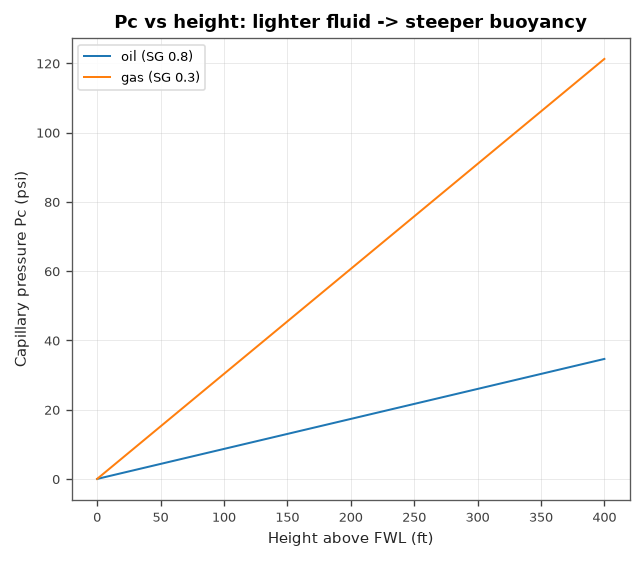

In [3]:
from petrophys.visualization import create_line_comparison

h = np.linspace(0, 400, 100)
series = {
    'oil (SG 0.8)': pc_from_height(h, sg_water, 0.8),
    'gas (SG 0.3)': pc_from_height(h, sg_water, 0.3),
}
# create_line_comparison plots each series vs a shared x; here x is HEIGHT and
# each series is the Pc it produces.
fig, ax = create_line_comparison(
    h, series,
    xlabel='Height above FWL (ft)', ylabel='Capillary pressure Pc (psi)',
    title='Pc vs height: lighter fluid -> steeper buoyancy',
    figsize=(6, 5),
)
plt.show()

Gas (lower SG) has a larger density contrast with water, so it develops the
same capillary pressure over a **shorter** height - gas columns build $P_c$
faster than oil columns.

## 2. Lab-to-reservoir Pc conversion

Core Pc is usually measured in an **air-mercury** or **air-brine** apparatus,
not at reservoir fluid conditions. The measured $P_c$ scales with the
interfacial tension and wettability of the fluid pair:

$$P_{c,res} = P_{c,lab}\,\frac{(\sigma\cos\theta)_{res}}{(\sigma\cos\theta)_{lab}}$$

`convert_pc_lab_to_reservoir` and the `FLUID_SYSTEMS` table make this a one-liner.
Air-mercury Pc is roughly an **order of magnitude** higher than the equivalent
oil-brine reservoir Pc (about 14x with the constants used here).

In [4]:
ift_lab, theta_lab = FLUID_SYSTEMS['air_mercury']   # (480, 140)
ift_res, theta_res = FLUID_SYSTEMS['oil_brine']      # (30, 30)

pc_lab = np.array([50, 100, 200, 500])               # psi, air-mercury
pc_res = convert_pc_lab_to_reservoir(pc_lab, ift_lab, theta_lab, ift_res, theta_res)

conv = pd.DataFrame({'Pc lab air-Hg (psi)': pc_lab, 'Pc res oil-brine (psi)': pc_res})
print(conv.to_string(index=False))
factor = (abs(ift_res * np.cos(np.radians(theta_res)))
          / abs(ift_lab * np.cos(np.radians(theta_lab))))
print('\nconversion factor (res/lab) = %.4f  (~1/%.1f)' % (factor, 1/factor))

 Pc lab air-Hg (psi)  Pc res oil-brine (psi)
                  50                3.532862
                 100                7.065724
                 200               14.131448
                 500               35.328621

conversion factor (res/lab) = 0.0707  (~1/14.2)


### 2b. Bundled laboratory Pc data

This lesson converts and fits capillary pressure without a measured drainage
curve, because none of the bundled data supports the complete plug-to-reservoir
workflow. The closest input is Craig Phillips's processed COSTA HPMI table,
`pp.sample("costa_core_pc")`: 110 sample IDs with PcHg, Sw, porosity and
permeability, enough for sample-level plots and QC. Its pressure units,
fluid-conversion metadata and plug-to-well/depth mapping must be verified
before the curves are converted to reservoir conditions or tied to a log, so
the lesson does not use it. The separate `costa_thomeer_fits` table holds
fitted results for 109 samples (sample 104 is absent). See the
[dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md).

## 3. Load the Kharaib-2 interval of HW-3

The HW-3 LAS in the COSTA sample set covers only the **Kharaib-2** carbonate
reservoir interval, not the whole well; the bundled COSTA tops
(`formations_costa`) label that interval. The file carries core-corrected
log porosity (`PHIE_CC`) and permeability (`PERM_CC`) and a source
water-saturation curve (`SW_INPUT`) - the log $S_w$ we will fit the J-function
to and later compare the model back against. Depth is in **feet**.

HW-3 carries no laboratory $P_c$ measurements. For a measured lab drainage
curve the library provides `fit_brooks_corey` (parameters $S_{wir}$, $P_d$,
$\lambda$); with no real lab data bundled we reference it rather than fabricate
a plug, and fit the **J-function** directly on the logged interval below.

In [5]:
well = pp.read(pp.sample("HW-3"))
interval = pp.read_formations(pp.sample("formations_costa"), well=well)
df = well.to_dataframe()
print("well      :", well.name)
print("depth unit:", well.depth_unit)
print("logged    : %.1f - %.1f ft" % (well.start_depth, well.stop_depth))
name, top, base = interval.iloc[0][["formation_name", "top_depth", "bottom_depth"]]
print("zone      : %s, %.1f - %.1f ft (the whole file)" % (name, top, base))
print("curves    :", well.curves)
for c in ["PHIE_CC", "PERM_CC", "SW_INPUT"]:
    cc = well.get(c)
    print("  %-9s valid=%3d  range %.3f - %.3f %s"
          % (c, cc.valid_count(), cc.min(), cc.max(), cc.unit))

well      : HW-3
depth unit: ft
logged    : 7805.0 - 8020.0 ft
zone      : KHARAIB-2, 7805.0 - 8020.0 ft (the whole file)
curves    : ['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC']
  PHIE_CC   valid=351  range 0.000 - 0.330 ft3/ft3
  PERM_CC   valid=355  range 0.010 - 990.000 mD
  SW_INPUT  valid=321  range 0.040 - 0.940 v/v


### Build a J-function from the rock-quality curves

We now fit the J-function on the HW-3 Kharaib-2 data. To turn each sample's
Sw into a $J$ value we need its $P_c$, which we obtain from an **assumed FWL
depth** just below the deepest valid sample (buoyancy converts height above
FWL into $P_c$). This follows the field workflow used when only saturation and
rock-quality data exist, except that there the FWL is picked from pressure
data; here it is an assumption, and every $J$ value inherits it.

In [6]:
depth = df['DEPTH'].values
phi = df['PHIE_CC'].values
perm = df['PERM_CC'].values
sw_log = df['SW_INPUT'].values

# Assumed free-water level a little below the deepest valid sample.
valid = np.isfinite(phi) & np.isfinite(perm) & np.isfinite(sw_log) & (phi > 0) & (perm > 0)
fwl_depth = np.nanmax(depth[valid]) + 20.0     # ft, assumed FWL pick
print('assumed FWL depth = %.1f ft' % fwl_depth)

height = np.clip(fwl_depth - depth, 0.0, None)              # ft above FWL
pc_core = pc_from_height(height, sg_water=1.0, sg_hc=0.8)   # psi
J_core = leverett_j(pc_core, perm, phi,
                    ift=FLUID_SYSTEMS['oil_brine'][0],
                    theta=FLUID_SYSTEMS['oil_brine'][1])

fit_ok = valid & np.isfinite(J_core) & (J_core > 0) & (sw_log > 0) & (sw_log <= 1)
print('points available to fit:', int(fit_ok.sum()))

model = fit_j_function(J_core[fit_ok], sw_log[fit_ok], form='power',
                       ift=FLUID_SYSTEMS['oil_brine'][0],
                       theta=FLUID_SYSTEMS['oil_brine'][1],
                       sg_water=1.0, sg_hc=0.8)
print('HW-3 J-function:  Sw = %.4f * J^(%.4f)   R2 = %.3f'
      % (model.a, model.b, model.r2))

assumed FWL depth = 8010.0 ft
points available to fit: 313
HW-3 J-function:  Sw = 0.0712 * J^(-0.2629)   R2 = 0.192


The $R^2$ printed above is low - carbonates are heterogeneous and our single
assumed FWL cannot reconcile every rock type. That is realistic; the model
still captures the first-order trend that better rock (higher $J$) drains to
lower $S_w$.

### 3a. Pick a formation pressure from a raw pretest

A station pressure starts as a raw pretest record: probe pressure against time
while the tool draws down and the formation builds back up. `read_mdt_pretest`
reads such a record and `pick_pressure()` accepts a stable buildup plateau or
returns the test for review. The bundled record is MDT file 059 from IODP Hole
C0009A (quartz gauge `BQP1`, tool depth `TDEP` in ft MD). The original DLIS,
`pp.sample("319-C0009A_MDT_059LTP")`, reads the same way with the `dlis` extra.

accepted 4102.13 psi at 9229.1 ft MD


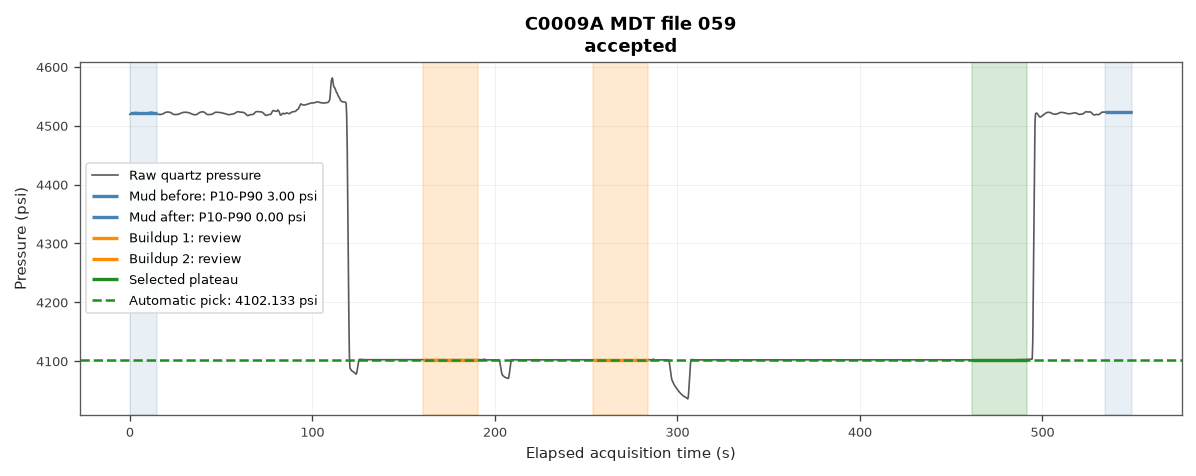

In [7]:
from petrophys.interpretation.saturation.height import read_mdt_pretest
from petrophys.visualization import create_mdt_pretest_plot

pretest = read_mdt_pretest(pp.sample("c0009a_mdt_059"), time_column="TIME",
                           pressure_column="BQP1", depth_column="TDEP")
pick = pretest.pick_pressure()
print(pick.status, round(pick.pressure, 2), pick.pressure_unit, "at", pick.station_depth, pick.depth_unit, "MD")
create_mdt_pretest_plot(pretest, pick, title="C0009A MDT file 059")
plt.show()

### 3b. Infer contacts from formation-pressure stations

The bundled station files hold one stabilized MDT pressure per test, one LAS
file per well: depth, formation and mud pressures, mobility and a test-quality
code. They carry no fluid labels. The library compares contiguous robust
pressure-gradient models and reports possible contacts or ambiguity.

The 35/11-13 LAS uses `QC=0` for valid pressure tests. We build the `USE_FIT`
selection from that curve: 21 good tests are included, including the shallow
gas stations. No fluid labels or report contacts are supplied to the fitter.


In [8]:
from petrophys.interpretation.saturation.height import read_formation_pressure
from petrophys.visualization import create_pressure_contact_plot
import lasio

station_las = lasio.read(pp.sample("35_11_13_mdt"))
# Select valid tests, including gas stations, using measurement QC only.
station_las.append_curve("USE_FIT", (station_las["QC"] == 0).astype(int))
pressure_data = read_formation_pressure(station_las)
pressure_fit = pressure_data.infer_contacts()
print("Selected stations:", int(pressure_data.points.use_fit.sum()))
print("Interpretation status:", pressure_fit.status)
print("Candidate fluid sequences:", pressure_fit.fluid_sequences)
print("FWL:", None if pressure_fit.fwl_depth is None else round(pressure_fit.fwl_depth, 2), "m TVD MSL")



Selected stations: 21
Interpretation status: interpreted
Candidate fluid sequences: (('oil', 'water'),)
FWL: 3113.17 m TVD MSL


Difference from report: +0.57 m


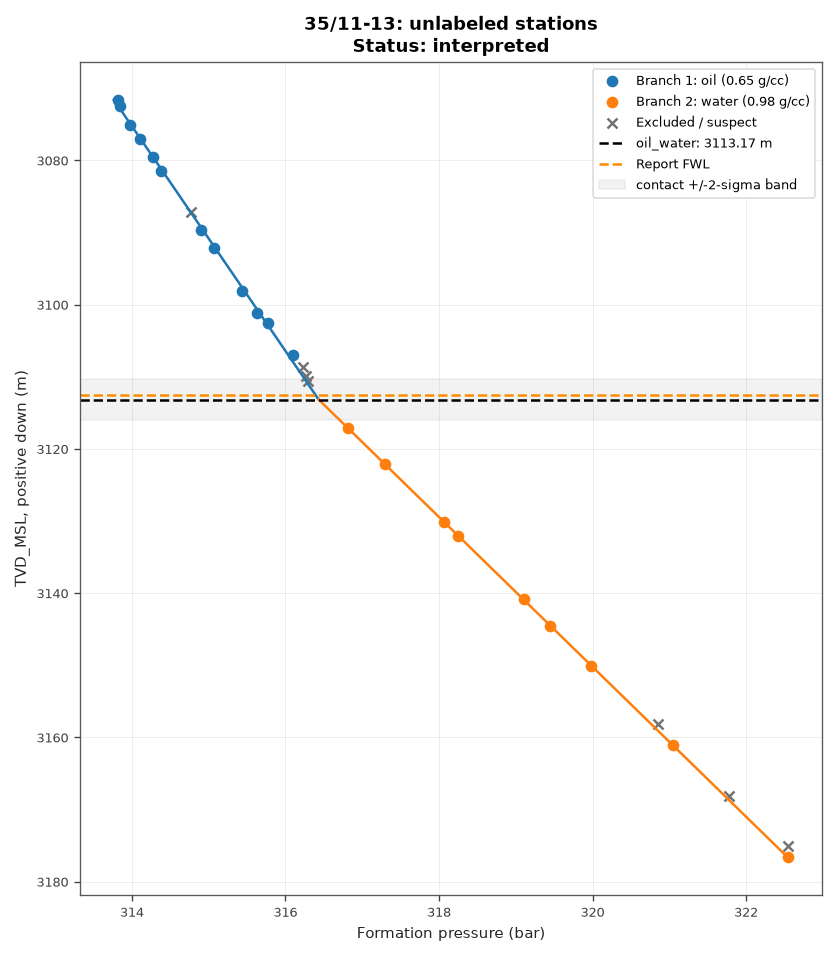

In [9]:
fig = create_pressure_contact_plot(pressure_data, pressure_fit, title="35/11-13: unlabeled stations")

# External verification only. The algorithm never receives this reported contact.
reported_fwl = 3112.6
assert pressure_fit.fwl_depth is not None
print(f"Difference from report: {pressure_fit.fwl_depth - reported_fwl:+.2f} m")
assert abs(pressure_fit.fwl_depth - reported_fwl) < 2.0
from matplotlib.patches import Patch
ax = fig.axes[0]
ax.axhline(reported_fwl, color="darkorange", linestyle="--", label="Report FWL")
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(color="0.5", alpha=0.10))
labels.append("contact +/-2-sigma band")
ax.legend(handles, labels, fontsize=8)
plt.show()

The default interpretation gives an oil/water candidate at **3113.2 m TVD MSL**,
about **0.6 m deeper** than the report. No contact intervals or fluid labels were
passed into it. The selected two-gradient model groups 12 shallow and 9 deeper
stations; it does **not resolve the two-station gas leg separately**. This is an
example of the limits of sparse pressure measurements, not proof that every
station in the upper branch contains oil. Branch-count scores and density
hypotheses are available on the result for review.

Shaded plot intervals are conditional +/-2-sigma sensitivity to pressure error
and fitted line scatter. They exclude fluid-prior, segmentation, connectivity
and depth-datum uncertainty; they are not field-accuracy guarantees.

### Second well: return ambiguity instead of forcing a contact

The 35/11-10 file holds every station of the well's MDT runs 1A-2E: pretests
and sampling stations from about 1950 to 2850 m TVD MSL. Contact inference assumes one connected reservoir, so we select
the Fensfjord interval (2250-2352 m TVD MSL) and its static pretests: valid
pressure (`QC=0`) and not a sampling station (`SAMPLE=0`), since pressures read
during sampling include drawdown. The report's **2290 m TVD MSL** contact is
used only in the comparison after inference, which the next cell prints and
draws.

Selected pretests: 13
Status: ambiguous
Definite FWL: None
Possible fluid sequences: (('oil', 'water'),)
Candidate intersection: 2290.70 m TVD MSL
Candidate minus report (2290 m): +0.70 m


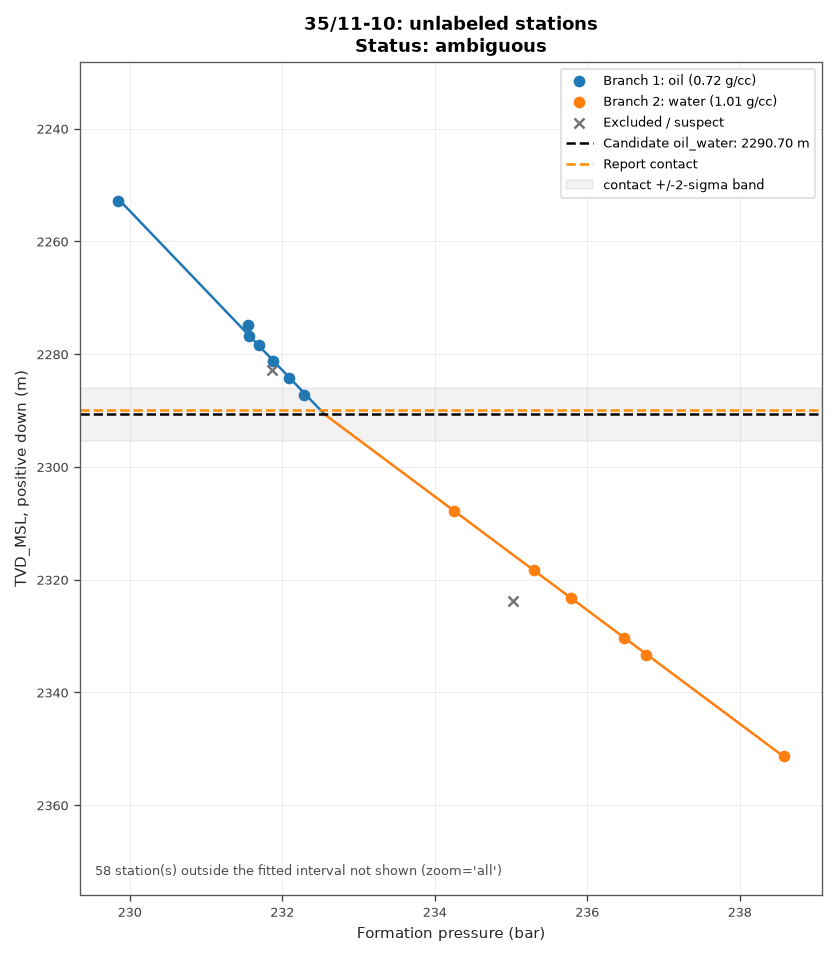

In [10]:
second_las = lasio.read(pp.sample("35_11_10_mdt"))
depth = second_las.index
fensfjord = (depth >= 2250) & (depth <= 2352)
static_pretest = (second_las["QC"] == 0) & (second_las["SAMPLE"] == 0)
second_las.append_curve("USE_FIT", (fensfjord & static_pretest).astype(int))
second_data = read_formation_pressure(second_las)
print("Selected pretests:", int(second_data.points.use_fit.sum()))
second_fit = second_data.infer_contacts()
print("Status:", second_fit.status)
print("Definite FWL:", second_fit.fwl_depth)
print("Possible fluid sequences:", second_fit.fluid_sequences)
for contact in second_fit.contacts:
    print(f"Candidate intersection: {contact.depth:.2f} m TVD MSL")
assert second_fit.status == "ambiguous" and second_fit.fwl_depth is None

# External comparison only, after inference: the report contact.
report_contact_10 = 2290.0
for contact in second_fit.contacts:
    print(f"Candidate minus report ({report_contact_10:.0f} m): {contact.depth - report_contact_10:+.2f} m")
fig = create_pressure_contact_plot(second_data, second_fit, title="35/11-10: unlabeled stations")
ax = fig.axes[0]
ax.axhline(report_contact_10, color="darkorange", linestyle="--", label="Report contact")
handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(color="0.5", alpha=0.10))
labels.append("contact +/-2-sigma band")
ax.legend(handles, labels, fontsize=8)
plt.show()


The two-branch intersection is approximately **2290.7 m**, within a metre of
the report's 2290 m contact (printed above). With 13 pretests, seven above the
contact and six below, the branch identification stays uncertain at the assumed pressure
error, so the method reports the result as ambiguous and leaves
`fwl_depth=None`. Changing `pressure_noise` changes model identifiability;
it must be grounded in measurement/picking quality, not tuned to a report contact.
Reservoir PVT density bounds can constrain `fluid_density_ranges` without
assigning individual stations. Independent samples/downhole fluid analysis and
geological connectivity provide stronger evidence than pressure alone.

For your own CSV or station LAS use `read_formation_pressure(path).infer_contacts()`.
Fluid labels are not needed. Map custom depth/pressure columns and provide units
and a TVD datum if absent. A `USE_FIT` mask must express measurement QC and the
reservoir interval, not known fluid intervals. For inputs with interpreted fluid labels, `.fit_fwl()` fits the labelled gradients.
Arbitrary hydraulic-compartment
discovery is outside this method.

Pressure alone **cannot determine a saturation-height function**. Separate
capillary-pressure/rock calibration and fluid properties are required.

**The next section returns to HW-3.** Its unrelated assumed FWL in feet remains
separate from these metre-based pressure examples.

## 4. Predict Sw vs depth from logs and overlay

`saturation_height_from_logs` takes the fitted J-function, an FWL depth, and the
well's permeability/porosity curves, and returns a **predicted $S_w$ at every
depth**. Height above the FWL is `fwl_depth - depth`; below the FWL height is
clipped to zero -> $S_w = 1$.

**Height is vertical.** `saturation_height_from_logs` measures it on a
true-vertical-depth curve when you name one (`tvd_curve=`); otherwise it takes
the well's depth index as TVD, which holds for a vertical well only, and says so
with a `UserWarning`. HW-3 carries no TVD curve or deviation survey, so we treat
it as vertical, with the assumed FWL on the same depth index, and the warning the
next cell prints records that assumption. A depth in metres would be converted to
feet for the field-unit capillary relation; HW-3 is already in feet.

One honesty note before reading the error statistic below: `SW_INPUT` is the
**same curve the J-function was fitted to**, so the mean absolute error is an
**in-sample goodness-of-fit check**, not independent prediction skill. Hold out
depths (or a whole well) from the fit for a real validation.

In [11]:
sw_pred = saturation_height_from_logs(
    well, model, fwl_depth=fwl_depth,
    perm_curve=('PERM_CC',), phi_curve=('PHIE_CC',),
    depth_increases_down=True,
)
print('predicted Sw: valid=%d  median=%.3f' % (np.isfinite(sw_pred).sum(),
                                               np.nanmedian(sw_pred)))

both = np.isfinite(sw_pred) & np.isfinite(sw_log)
resid = sw_pred[both] - sw_log[both]
print('vs log Sw: mean abs error = %.3f, bias = %+.3f'
      % (np.nanmean(np.abs(resid)), np.nanmean(resid)))

predicted Sw: valid=324  median=0.090
vs log Sw: mean abs error = 0.028, bias = -0.011


[temporary directory]\ipykernel_25976\1502046029.py:1: UserWarning: saturation_height_from_logs: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only. Pass tvd_curve, on the datum of fwl_depth, for a deviated well.
  sw_pred = saturation_height_from_logs(


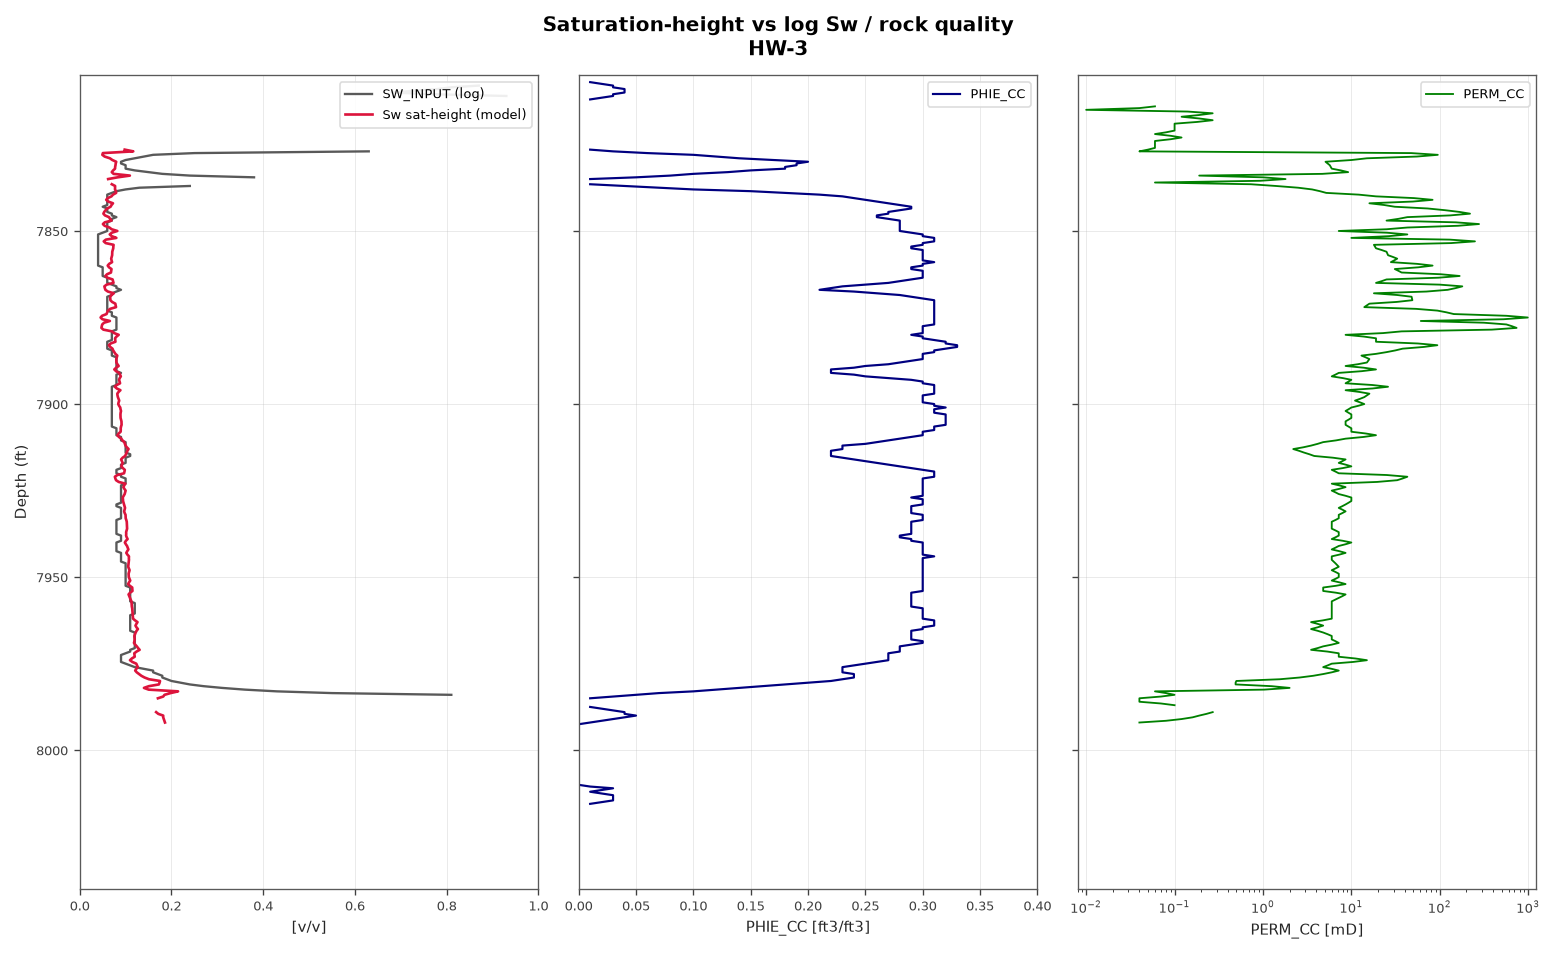

In [12]:
from petrophys.visualization import LogPlot

# Attach the predicted saturation-height Sw so a library plotter can render it.
well.add_curve('SW_SATHEIGHT', sw_pred, unit='v/v', description='Sw from sat-height model')

lp = LogPlot(well, figsize=(13, 8))
lp.create_figure(n_tracks=3)
# Track 0: log Sw vs saturation-height Sw
lp.add_curve(0, 'SW_INPUT', color='0.35', linewidth=1.4, xlim=(0, 1), label='SW_INPUT (log)')
lp.add_curve(0, 'SW_SATHEIGHT', color='crimson', linewidth=1.6, xlim=(0, 1),
             label='Sw sat-height (model)')
# Separate porosity and permeability scales so their units stay explicit.
lp.add_curve(1, 'PHIE_CC', color='navy', linewidth=1.3, xlim=(0, 0.4), label='PHIE_CC')
lp.add_curve(2, 'PERM_CC', color='green', linewidth=1.1, log_scale=True, label='PERM_CC')
lp.set_depth_range(top=well.start_depth, bottom=fwl_depth + 30)
lp.axes[0].set_ylabel(f"Depth ({well.depth_unit})")
lp.add_title('Saturation-height vs log Sw / rock quality')
lp.show()

Where the two $S_w$ curves diverge is diagnostic: if the saturation-height
model reads **drier** than the log $S_w$, either the FWL is picked too deep, the
rock-quality curves are off, or there is a genuine transition-zone /
low-resistivity-pay effect worth investigating.

## 5. The library's saturation-height diagnostic plot

`create_saturation_height_plot` renders the standard two-panel QC: the
**J-function fit** over the fitted points (left) and the resulting **Sw-vs-height
type curves** for a set of rock classes (right). HW-3 has no core saturations or
lab $P_c$, so the points are the `SW_INPUT` log saturations, with $J$ computed
from the assumed FWL; `data_label` names them that way in the legend. This is
the layout of a saturation-height report plot, but a report version needs
measured $P_c$ or a pressure-derived FWL behind it.

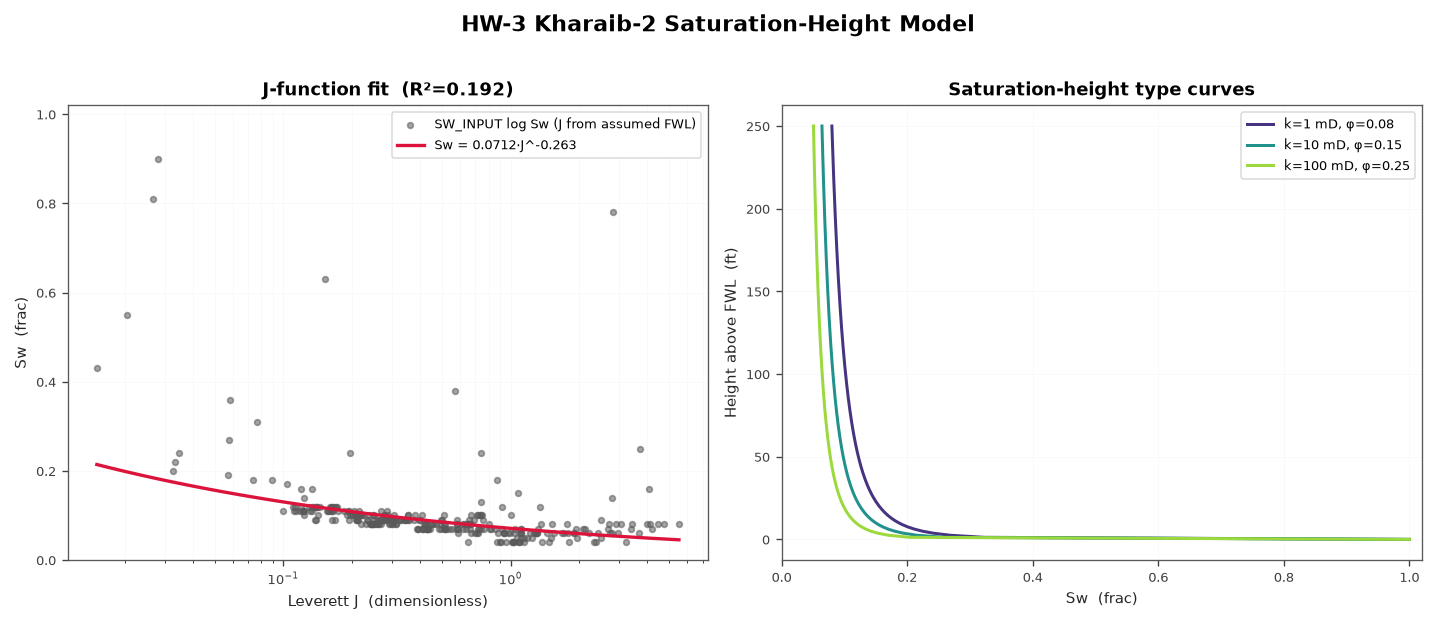

In [13]:
from petrophys.visualization import create_saturation_height_plot

fig = create_saturation_height_plot(
    model,
    j=J_core[fit_ok],
    sw=sw_log[fit_ok],
    rock_classes=[(1.0, 0.08), (10.0, 0.15), (100.0, 0.25)],
    max_height_ft=250.0,
    title='HW-3 Kharaib-2 Saturation-Height Model',
    data_label='SW_INPUT log Sw (J from assumed FWL)',
)
plt.show()

The right-hand type curves show the model's core prediction: at any given
height above the FWL, **better rock (higher $k$, higher $\phi$) holds less
water** - exactly the capillary physics we started with. In a calibrated study,
curves like these are what get handed to the reservoir model to populate $S_w$
away from well control. These ones are not ready for that: the fit explains
only a small part of the scatter ($R^2$ printed in the panel title), it is fitted
to log saturations rather than measured $P_c$, and the FWL behind every $J$ value
is assumed. Treat them as a demonstration of the method.

## Pitfalls & parameter choices

- **The FWL must come from data.** For HW-3 we *assumed* an FWL 20 ft below the
  deepest valid sample to make the demo self-contained; in practice pick it from formation
  pressures (RFT/MDT gradient intersection) or the deepest known water. A wrong
  FWL biases every predicted $S_w$.
- **J-function vs Brooks-Corey.** J-function normalises by $\sqrt{k/\phi}$, so **one**
  fit covers many rock qualities and is the model applied back to logs.
  Brooks-Corey describes a **single** drainage curve - fit it per rock type / per
  plug.
- **Always lab-to-reservoir convert Pc.** Never fit reservoir saturations to raw
  air-mercury Pc; use `convert_pc_lab_to_reservoir` first.
- **Units.** The capillary-pressure functions use field units: Pc in psi, height in ft, $k$
  in mD, $\phi$ as a **fraction**, IFT in dyne/cm, angle in degrees.
  `saturation_height_from_logs` converts a depth in metres to feet itself.
- **Height is vertical.** Pass `tvd_curve=` for a deviated well, on the datum of
  the FWL; without it the depth index is taken as TVD, with a warning.
- **Modest $R^2$ is normal** in heterogeneous carbonates; consider fitting
  separate J-functions per flow unit / rock type.

## Recap

- **Height above the FWL is a rescaled capillary pressure**:
  $P_c = 0.433(\mathrm{SG}_w-\mathrm{SG}_{hc})h$.
- The **Leverett J-function** normalises $P_c$ by $\sqrt{k/\phi}$ so different rock
  qualities collapse onto one curve.
- **Brooks-Corey** ($S_{wir}, P_d, \lambda$) describes a single drainage curve;
  the **J power-law** ($S_w = aJ^b$) is what we apply back to logs.
- Lab Pc must be **converted to reservoir** fluid conditions before use.
- `saturation_height_from_logs` turns a fitted model + FWL + $(k,\phi)$ curves
  into a predicted $S_w$ profile you can overlay on the resistivity-based
  $S_w$ (here an in-sample comparison, since the same curve trained the fit).
- The 35/11-13 MDT example fits FWL from oil/water pressure gradients and
  checks it against the source report, keeping TVD, units and QC explicit.


## Try it yourself

> **Exercise 1.** Move the assumed FWL up and down by +/-30 ft and re-run the
> prediction. How sensitive is the mean absolute error to the FWL pick?
>
> **Exercise 2.** Fit the J-function with `form='power_swir'` and an explicit
> `swir=0.1` floor. Does forcing an irreducible asymptote improve the deep,
> tight-rock predictions?
>
> **Exercise 3.** Using the fitted HW-3 Kharaib-2 J-function (`model`), compute the height
> above the FWL at which $S_w$ first falls below 0.5 for a 10 mD / 0.15 rock
> versus a 100 mD / 0.25 rock (hint: invert $S_w = a\,J^b$ for $J$, then
> `pc_from_j` and `height_from_pc`).

## What's next

Continue with **16 - Borehole Images and FMI**. Part B then runs through
lesson 21: 17 (visualization masterclass), 18 (multiwell field study), 19 (LLM
context generation), 20 (Petrophys for LLM agents over MCP) and 21 (custom
workflows). Along the way,
revisit the Part A water-saturation lesson (07) and compare its Archie $S_w$
against this saturation-height prediction - reconciling the two is the heart
of a defensible reservoir saturation model.